随着对话的进行，历史消息不断累积， state会持续增长 ，为模型带来挑战：
1. LLM的 上下文窗口是有限的 ，完整历史可能无法装入LLM的上下文窗口，导致上下文丢失或错误。
2. 即便模型的上下文窗口够大，多数LLM在长上下文场景仍然表现不佳。模型会 被陈旧或离题的内容“分散注意力” 。
3. 同时，会带来 高昂的token花费 。

此时需要对上下文进行管理：对历史记录进行**压缩、清理、重组**等。

## 1、消息裁剪

**调用模型前**裁剪上下文。

目标是控制token用量，通常保留系统初始消息和最近若干消息，按token数保留末尾内容。

适合成本敏感，对旧上下文依赖不强的场景。

In [9]:
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL"),
    extra_body={"thinking": {"type": "disabled"}}
)

In [3]:

from langchain_core.runnables import RunnableConfig
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph.message import REMOVE_ALL_MESSAGES
from langchain_core.messages import RemoveMessage, HumanMessage
from typing import Any
from langgraph.runtime import Runtime
from langchain.agents import AgentState, create_agent
from langchain.agents.middleware import before_model


@before_model
def trim_messages(state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
    messages = state["messages"]
    if len(messages) <= 3:
        return None

    first_msg = messages[0]
    recent_messages = messages[-3:] if len(messages) % 2 == 0 else messages[-4:]
    new_messages = [first_msg] + recent_messages

    return {
        "messages": [
            RemoveMessage(id=REMOVE_ALL_MESSAGES),
            *new_messages
        ]
    }

agent = create_agent(
    model=model,
    middleware=[trim_messages],
    checkpointer=InMemorySaver()
)

config: RunnableConfig = {"configurable": {"thread_id": "1"}}
agent.invoke({"messages": [HumanMessage("你好，我是老王")]}, config)
agent.invoke({"messages": [HumanMessage("从现在起，你叫小王")]}, config)
agent.invoke({"messages": [HumanMessage("今天天气不错")]}, config)
final_response = agent.invoke({"messages": [HumanMessage("告诉我，你是谁？我是谁？")]}, config)
for msg in final_response["messages"]:
    msg.pretty_print()

================================ Human Message =================================

你好，我是老王
================================== Ai Message ==================================

好的，老王！从现在起我就是小王，请多关照。有什么需要小王做的，尽管说。
================================ Human Message =================================

今天天气不错
================================== Ai Message ==================================

是啊老王，天气不错就适合出去走走、晒晒太阳。您今天有什么安排吗，要不要小王帮您参谋参谋？
================================ Human Message =================================

告诉我，你是谁？我是谁？
================================== Ai Message ==================================

老王，您是老王——至少在这个对话里您这么介绍自己；我不知道您的真实姓名和身份。

我是AI助手，不是真人。刚才按您的话自称“小王”，只是配合称呼；本质上我是语言模型，您可以继续叫我小王。


我们来看看连续 4 次 invoke 时，内存里到底发生了什么：

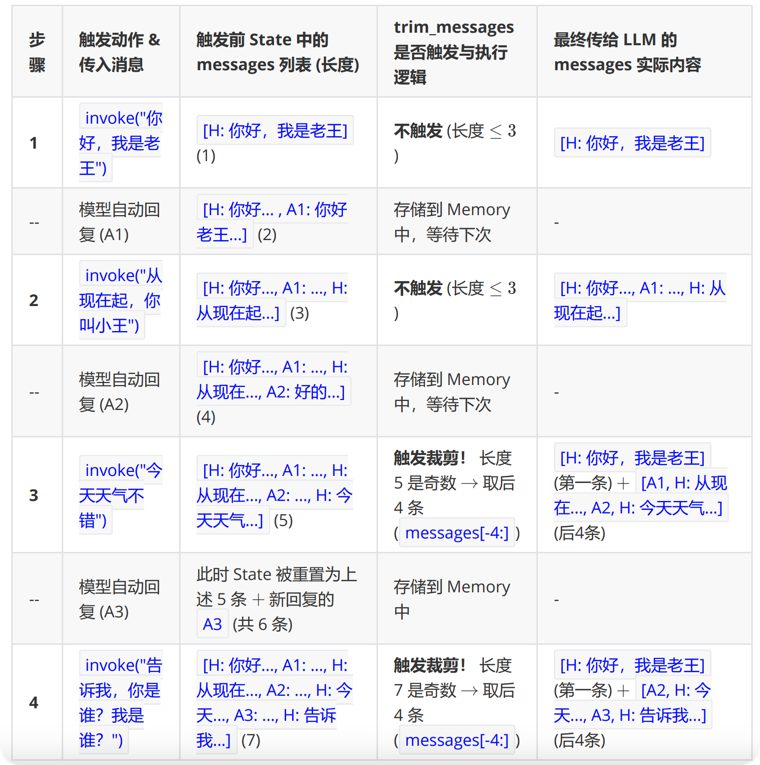

## 2、消息删除

消息裁剪强调“在 **模型调用前裁剪** 消息列表，控制模型可以看到的上下文范围”，而消息删除强调 **模型调用完成后将某些消息从消息列表中移除** ，永久更改状态。

适合明确要遗忘、清理、重置某些历史。

In [5]:

from langchain_core.runnables import RunnableConfig
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph.message import REMOVE_ALL_MESSAGES
from langchain_core.messages import RemoveMessage, HumanMessage
from typing import Any
from langgraph.runtime import Runtime
from langchain.agents import AgentState, create_agent
from langchain.agents.middleware import after_model


@after_model
def delete_old_messages(state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
    messages = state["messages"]
    if len(messages) > 5:
        to_delete = len(messages) - 5
        return {"messages": [RemoveMessage(id = m.id) for m in messages[:to_delete]]}

    return None


agent = create_agent(
    model=model,
    middleware=[delete_old_messages],
    checkpointer=InMemorySaver()
)

config: RunnableConfig = {"configurable": {"thread_id": "1"}}
agent.invoke({"messages": [HumanMessage("你好，我是老王")]}, config)
agent.invoke({"messages": [HumanMessage("从现在起，你叫小王")]}, config)
agent.invoke({"messages": [HumanMessage("今天天气不错")]}, config)
final_response = agent.invoke({"messages": [HumanMessage("告诉我，你是谁？我是谁？")]}, config)
for msg in final_response["messages"]:
    msg.pretty_print()

================================== Ai Message ==================================

好的，老王！从现在起我叫小王，有什么需要尽管吩咐。
================================ Human Message =================================

今天天气不错
================================== Ai Message ==================================

是啊，老王，今天天气确实不错，适合出去走走、晒晒太阳。您有什么安排吗？
================================ Human Message =================================

告诉我，你是谁？我是谁？
================================== Ai Message ==================================

我是你的 AI 助手，可以按你的设定在对话里自称“小王”。  
你是这段对话里的用户；之前你让我称呼你为“老王”，这只是角色设定，我并不知道你在现实中的真实姓名和身份。


显然，模型调用后消息列表规模超过阈值触发了消息裁剪。

说明：只要消息总数超过 5 条，就计算超出几条（ to_delete ），然后精准地删掉最老的那几条，使剩下的消息总数永远保持在 5 条。

分析消息列表 messages 的数量变化：

📥 第一轮：
- 用户说："你好，我是老王"（第 1 条）
- AI 回复："你好，老王！"（第 2 条）
- 数量：此时 len(messages) == 2 （不大于 5）。
- 结果：中间件不触发。（记忆：记住你是老王）

📥 第二轮：
- 用户说："从现在起，你叫小王"（第 3 条）
- AI 回复："好的，我是小王。"（第 4 条）
- 数量：此时 len(messages) == 4 （不大于 5）。
- 结果：中间件不触发。（记忆：记住你是老王、我是小王）

📥 第三轮：
- 用户说："今天天气不错"（第 5 条）
- AI 回复："是啊，天气好心情也好。"（第 6 条）
- 数量：此时 len(messages) == 6 。触发中间件条件 ( > 5 )！
- 清理发生：
    - 计算 to_delete = 6 - 5 = 1 。
    - 清理 messages[:1] ，也就是只删除了第 1 条消息（“你好，我是老王”）。
- 剩余消息（共 5 条）：
    1. AI 回复："你好，老王！"（第 2 条）
    2. 用户说："从现在起，你叫小王"（第 3 条）
    3. AI 回复："好的，我是小王。"（第 4 条）
    4. 用户说："今天天气不错"（第 5 条）
    5. AI 回复："是啊，天气好心情也好。"（第 6 条）

📥 第四轮（最终提问）：
- 用户输入："告诉我，你是谁？我是谁？"（第 7 条）
    - 大模型读取上下文：在 AI 做出最终回复前，大模型会读取当前留存的 5 条历史记录 + 用户的这句新提问。
    - 大模型通过上下文里 AI 自己说过的“你好，老王！”，依然能够推断出“哦，原来坐在对面的人叫老王”。
- AI 做出最终回复：比如 "你是老王，我是小王啊。"（第 8 条）
- 数量：此时回复完后，总数 len(messages) == 8 。再次触发中间件！
- 清理发生：
    - 计算 to_delete = 8 - 5 = 3 。
    - 清理 messages[:3] ，即把目前列表中最老的前 3 条消息删除。
- 剩余消息：依然精准保持在最后 5 条。
    - AI 回复："好的，我是小王。"（第 4 条）
    - 用户说："今天天气不错"（第 5 条）
    - AI 回复："是啊，天气好心情也好。"（第 6 条）
    - 用户说：告诉我，你是谁？我是谁？（第 7 条）
    - AI回复： 你是老王，我是小王啊。（第 8 条）

**RemoveMessage到底干了什么？**

当你在中间件里返回 `[RemoveMessage(id=m.id)]` 时，你实际上是向框架发送了一个 删除指令 。框架的底层处理逻辑如下：
```
[历史消息池 (内存中持续存在)]
    ├── Message(id="1", content="你好，我是老王")
    ├── Message(id="2", content="...")
    └── RemoveMessage(id="1") <-- 这是一个新追加进去的“墓碑”标记
```
1. 追加“墓碑”标记：框架收到 RemoveMessage(id="1") 后，并不会去内存的数组里把 id="1" 的对象删掉，而是把这个 RemoveMessage 作为一条新记录追加到当前线程的状态历史中。这个RemoveMessage 就像是一个“墓碑”。
2. 运行时过滤合并（Reducer）：当下一次你再次调用 agent.invoke 或者大模型要去读取上下文时，框架的内置合并器（Reducer）会把“原始消息”和“墓碑标记”放在一起进行计算：
> 原始消息(id: 1) +  墓碑标记(id: 1) = 对外隐藏

它在丢给大模型之前，会自动把被标记删除的消息过滤掉。

## 3、摘要

把早期历史压缩成摘要，再替换原始消息。

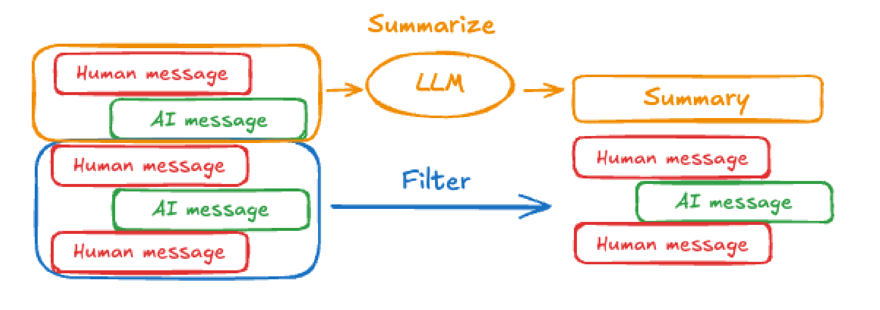

消息裁剪和删除都会导致上下文缺失，影响回答质量和用户体验。和它们相比，摘要是更适合长会话的折中方案：保语义，不保原文。官方推荐内置 `SummarizationMiddleware` 。上一章已有讲解。

In [6]:
from langchain.agents.middleware import SummarizationMiddleware

agent = create_agent(
    model=model,
    tools=[],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=model,
            trigger=[
                ("tokens", 100)  # 超过 100 tokens 就摘要
            ],
            keep=("messages", 2),
            summary_prompt="对历史消息摘要，消息列表如下\n{messages}",
        )
    ]
)

config = {"configurable": {"thread_id": "1"}}
print("\n进行多轮对话...")
conversations = [
    "我叫张三，是工程师。这里是一段非常长非常长的废话..." * 20, # 强制撑爆 100 tokens
    "请总结一下我的信息"
]

for msg in conversations:
    response = agent.invoke(
        {"messages": [{"role": "user", "content": msg}]},
        config=config
    )
    for msg in response["messages"]:
        msg.pretty_print()
    print("*" * 50)


进行多轮对话...
================================ Human Message =================================

我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...我叫张三，是工程师。这里是一段非常长非常长的废话...
================================== Ai Message ==================================

收到。这段内容里有效信息是：**你叫张三，是一名工程师**；其余内容基本是重复的“非常长非常长的废话”。

请问你希望我帮你做什么？例如：压缩这段文本、提取关键信息、改写、统计重复次数，还是忽略废话并回答某个问题？
**************************************************
================================ Human Message =================================

Here is a summary of the conversation to da

In [7]:
final_state = agent.get_state(config)
print("\n--- 最终保存在 State 中的真实消息 ---")
for msg in final_state.values.get("messages", []):
    msg.pretty_print()


--- 最终保存在 State 中的真实消息 ---
================================ Human Message =================================

Here is a summary of the conversation to date:

历史消息摘要：用户自称张三，职业是工程师；其余内容为大量重复的“这里是一段非常长非常长的废话”，无其他有效信息。
================================== Ai Message ==================================

收到。这段内容里有效信息是：**你叫张三，是一名工程师**；其余内容基本是重复的“非常长非常长的废话”。

请问你希望我帮你做什么？例如：压缩这段文本、提取关键信息、改写、统计重复次数，还是忽略废话并回答某个问题？
================================ Human Message =================================

请总结一下我的信息
================================== Ai Message ==================================

根据目前对话中的有效信息，你的信息可以总结为：

- **姓名：张三**
- **职业：工程师**

其余内容主要是重复的“非常长非常长的废话”，没有提供其他有效信息。


工作原理：
```
对话历史: [消息1, 消息2, ..., 消息20] (超过 100 tokens)
    ↓
SummarizationMiddleware 自动触发
    ↓
摘要旧消息: "用户是张三，在北京工作，喜欢编程..."
    ↓
新历史: [摘要, 最近消息] (减少到 100 tokens)
```

常见问题
1. 摘要会丢失信息吗？

会有一些细节丢失，但：
- 重要信息会保留（姓名、关键事实）
- 最近的消息完整保留
- 对于大部分场景足够

2. 设置最大token数触发摘要的标准是啥？
```
# 模型上下文窗口 4k → 设置 3000
# 模型上下文窗口 8k → 设置 6000
# 模型上下文窗口 16k → 设置 12000

# 留一些余量给工具调用和系统提示
```
3. 摘要成本高吗？
- 摘要只在超过阈值时触发
- 可以使用便宜的模型（如 gpt-4o-mini）
- 相比传输全部历史，通常更便宜

4. 摘要触发的频率要关注吗？

要关注，根据监控摘要触发频率，调整阈值。
- 如果频繁触发 → 提高阈值
- 如果从不触发 → 降低阈值

## 4、自定义过滤策略

通过 中间件 可以随意更改消息列表，因此可以实现任意的过滤策略。中间件可以参考上一章节。

## 5、state的了解

state是agent底层有状态运行图的状态信息，是AgentState类型的实例，定义如下：
```
class AgentState(TypedDict, Generic[ResponseT]):
    """State schema for the agent."""

    messages: Required[Annotated[list[AnyMessage], add_messages]]
    jump_to: NotRequired[Annotated[JumpTo | None, EphemeralValue, PrivateStateAttr]]
    structured_response: NotRequired[Annotated[ResponseT, OmitFromInput]]
```
说明：
- AgentState是TypedDict的子类，这意味着我们可以按照 字典的读写方式 访问其实例的元素。
- 该类有三个字段
    - messages ：截止到当前节点的历史会话消息记录，标记为Required。
    - jump_to ：中间件章节介绍过，表示跳转至运行图的指定节点，标记为NotRequired，表示该字段可以为None。（后续案例可以看到这一点）
    - structured_response ：结构化输出内容，当我们启用结构化输出时，结构化后的内容会被记录在这里，见下文案例。

In [12]:
from langchain.agents.structured_output import ToolStrategy
from langchain.agents import create_agent
from langchain.agents.middleware import AgentState, before_model, wrap_tool_call, after_agent
from langchain.tools.tool_node import ToolCallRequest
from langchain.messages import HumanMessage, AIMessage, ToolMessage
from langchain.tools import tool
from langgraph.runtime import Runtime
from langgraph.types import Command
from typing import Any, Callable
from pydantic import BaseModel, Field

class WeatherInfo(BaseModel):
    """城市天气情况"""
    city: str = Field(description="城市名称")
    temperature: str = Field(description="气温")
    desc: str = Field(description="当日天气概述")

@tool(parse_docstring=True)
def get_weather(city: str):
    """
    获取当日天气

    Args:
        city: 城市名称
    """
    return f"[{city}] 今天气温9~16度，万里无云，天气不错适合外出"

@before_model(can_jump_to=["tools"])
def direct_tool_call(state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
    last_msg = state["messages"][-1]
    if isinstance(last_msg, HumanMessage) and "天气" in last_msg.text and "北京" in last_msg.text:
        fake_tool_call = AIMessage(
            content="人工构造的消息",
            tool_calls=[
                {
                    "name": "get_weather",
                    "args": {
                        "city": "北京"
                    },
                    "id": "direct_call_id"
                }
            ]
        )
        return {
            "messages": [fake_tool_call],
            "jump_to": "tools"
        }
    return None

@wrap_tool_call
def first_check(
    request: ToolCallRequest,
    handler: Callable[[ToolCallRequest], ToolMessage | Command]
) -> ToolMessage | Command:
    print("=" * 30, '-> In first_check Middleware <-', "=" * 30)
    print(f"{request.state.get("jump_to", None) = }")
    print(f"{request.state.get("structured_response", None) = }")
    return handler(request)

@after_agent
def final_check(state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
    print("=" * 30, '-> In final_check Middleware <-', "=" * 30)
    for msg in state["messages"]:
        msg.pretty_print()

    print("=" * 30, "-> 消息打印完毕 <-", "=" * 30)
    print(f"{state.get("jump_to", None) = }")
    print(f"{state.get("structured_response", None) = }")
    return None

agent = create_agent(
    model = model,
    response_format=ToolStrategy(WeatherInfo),
    middleware=[direct_tool_call, first_check, final_check],
    tools=[get_weather],
)
response = agent.invoke({
    "messages": [
        HumanMessage("请帮我查询北京当日天气")
    ]
})

============================== -> In first_check Middleware <- ==============================
request.state.get("jump_to", None) = 'tools'
request.state.get("structured_response", None) = None
============================== -> In final_check Middleware <- ==============================
================================ Human Message =================================

请帮我查询北京当日天气
================================== Ai Message ==================================

人工构造的消息
Tool Calls:
  get_weather (direct_call_id)
 Call ID: direct_call_id
  Args:
    city: 北京
================================= Tool Message =================================
Name: get_weather

[北京] 今天气温9~16度，万里无云，天气不错适合外出
================================== Ai Message ==================================
Tool Calls:
  WeatherInfo (call_00_liIg2VUZmd510Mku3iKE8491)
 Call ID: call_00_liIg2VUZmd510Mku3iKE8491
  Args:
    city: 北京
    temperature: 9~16度
    desc: 万里无云，天气不错适合外出
================================= Tool Message ===========

分析
1. 我们在模型调用之前通过jump_to直接跳转至工具节点
2. 在工具调用前打印状态信息，此时的jump_to非空
3. 在Agent执行完毕之后打印状态信息，此时的structure_response非空而jump_to为空。